# Projet · Les annulations de deux hôtels
**Master 1 CGAO · IA et Machine Learning · évaluation finale**

## Le sujet
Vous êtes les contrôleurs de gestion de deux hôtels portugais : un hôtel de ville à **Lisbonne** et un hôtel de bord de mer en **Algarve**. Plus d'une réservation sur trois est annulée. La direction vous demande :
1. **des indicateurs fiables** : chiffre d'affaires, nuits vendues, prix moyen, annulations, par hôtel et par mois ;
2. **un outil qui signale, dès la réservation, celles qui risquent d'être annulées** ;
3. **un tableau de bord** qui réunit les deux, pour piloter.

## Les données
Les 119 390 réservations réelles des deux hôtels, pour des arrivées du 1er juillet 2015 au 31 août 2017, extraites de leur logiciel de gestion (Antonio, de Almeida et Nunes, *Hotel booking demand datasets*, Data in Brief, 2019, licence CC BY 4.0). **Une ligne = une réservation.** Le fichier a été simplifié : 19 colonnes, noms et libellés traduits, nuits de semaine et de week-end additionnées. Les réservations et leurs valeurs n'ont pas été modifiées, anomalies comprises.

## Les étapes
| Étape | Ce que vous produisez | Quand |
|---|---|---|
| 1 · Les données | un fichier propre et le chiffre d'affaires de chaque réservation | TD 2 |
| 2 · Les indicateurs | les indicateurs de gestion et leurs graphiques | TD 2 |
| 3 · Le modèle | un modèle qui prévoit les annulations, évalué honnêtement | TD 2, à terminer |
| 4 · Le tableau de bord | une application Streamlit en ligne | TD 3 |

## Ce que vous rendrez
- ce notebook, complet, avec la **note pour la direction** et l'**usage de l'IA** (à la fin) ;
- votre tableau de bord Streamlit : **son lien**, qui doit s'ouvrir sans compte depuis n'importe quel navigateur, et son fichier `app.py` (TD 3).

Groupes de 2 ou 3. Nom du fichier : `Projet_NOM1_NOM2.ipynb`.

## Ce qui est évalué
- **les données** : les contrôles faits, les choix justifiés ;
- **les indicateurs** : bien définis, justes, utiles à la direction, bien présentés ;
- **le modèle** : comparé à une référence, sans fuite de données, avec un seuil justifié ;
- **le tableau de bord** : lisible, en ligne, fidèle à vos résultats ;
- **la note et l'usage de l'IA** : clairs, chaque chiffre vérifié.

## Comment travailler dans ce notebook
- Exécutez les cellules **dans l'ordre**, de haut en bas (`Maj + Entrée`).
- 🔧 **À vous** : un énoncé, puis une cellule vide où vous écrivez votre code.
- ✍️ **Question** : double-cliquez dans la cellule *Votre réponse* pour écrire.
- C'est votre projet : les énoncés disent **ce qu'il faut produire**, les aides indiquent **l'outil**, jamais la réponse. Les choix (ce que vous retirez, comment vous calculez, quelles variables vous gardez, quel seuil) sont les vôtres, et doivent être justifiés.
- Le notebook de classification de la première heure vous sert de **modèle** pour l'étape 3.

> **Assistant d'IA.** Vous pouvez vous faire aider, pour comprendre une erreur ou une notion, ou pour écrire du code. Notez-le dans la dernière section : pour quoi faire, avec quel prompt, et ce que vous avez vérifié. Vous devez pouvoir expliquer chaque ligne que vous rendez.

# Étape 1 · Comprendre et préparer les données

## Le dictionnaire des variables
| Colonne | Contenu |
|---|---|
| `reservation` | numéro de la réservation |
| `hotel` | `Lisbonne` (hôtel de ville) ou `Algarve` (hôtel de bord de mer) |
| `date_arrivee` | date d'arrivée prévue, écrite année-mois-jour |
| `annee`, `mois` | année et mois d'arrivée |
| `delai_reservation` | nombre de jours entre la réservation et l'arrivée prévue |
| `nuits` | nombre de nuits réservées |
| `adultes`, `enfants` | nombre d'adultes et d'enfants |
| `segment` | origine de la réservation : agence en ligne, agence ou voyagiste, groupe, direct, entreprise, offert, aviation |
| `type_client` | individuel, individuel lié à une autre réservation, groupe, contrat |
| `client_habitue` | 1 si le client a déjà séjourné dans l'hôtel |
| `annulations_precedentes` | nombre de réservations que le client avait déjà annulées |
| `depot` | sans dépôt, remboursable, non remboursable (dépôt égal au prix du séjour) |
| `prix_nuit` | prix moyen d'une nuit pour cette réservation, en euros (les deux hôtels sont au Portugal ; l'article ne précise pas la devise) |
| `demandes_speciales` | nombre de demandes particulières (lit double, étage élevé…) |
| `chambre_changee` | 1 si la chambre attribuée diffère de la chambre réservée |
| `statut_final` | dernier statut : séjour effectué, annulée, non présenté |
| `annulee` | **la cible** : 1 si la réservation a été annulée ou si le client ne s'est pas présenté, 0 sinon |

Déposez `reservations_hotels.csv` dans le panneau 📁 de Colab, puis exécutez la cellule.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def fr(nombre, decimales=0):
    # écrit un nombre à la française : 25 950 266 ou 0,76
    return f"{nombre:,.{decimales}f}".replace(",", " ").replace(".", ",")

def pc(proportion):
    # écrit une proportion en pourcentage : 37,3 %
    return f"{100 * proportion:.1f}".replace(".", ",") + " %"

donnees = pd.read_csv("reservations_hotels.csv")
print(fr(len(donnees)), "réservations,", donnees.shape[1], "colonnes")
donnees.head()

119 390 réservations, 19 colonnes


,reservation,hotel,date_arrivee,annee,mois,delai_reservation,nuits,adultes,enfants,segment,type_client,client_habitue,annulations_precedentes,depot,prix_nuit,demandes_speciales,chambre_changee,statut_final,annulee
0,1,Algarve,2015-07-01,2015,7,342,0,2,0.0,Direct,Individuel,0,0,Sans dépôt,0.0,0,0,Séjour effectué,0
1,2,Algarve,2015-07-01,2015,7,737,0,2,0.0,Direct,Individuel,0,0,Sans dépôt,0.0,0,0,Séjour effectué,0
2,3,Algarve,2015-07-01,2015,7,7,1,1,0.0,Direct,Individuel,0,0,Sans dépôt,75.0,0,1,Séjour effectué,0
3,4,Algarve,2015-07-01,2015,7,13,1,1,0.0,Entreprise,Individuel,0,0,Sans dépôt,75.0,0,0,Séjour effectué,0
4,5,Algarve,2015-07-01,2015,7,14,2,2,0.0,Agence en ligne,Individuel,0,0,Sans dépôt,98.0,1,0,Séjour effectué,0


### ✍️ 1.1 · Question
Lisez le dictionnaire. Pour chaque colonne : quand la connaît-on, à la réservation, à l'arrivée du client, ou après ? Lesquelles ne sont connues qu'**après** la réservation ? Gardez votre réponse : elle servira à l'étape 3.

*Votre réponse :*

- À la réservation, on connaît : reservation (le numéro), hotel, date_arrivee, annee et mois, delai_reservation, nuits (les nuits réservées, donc prévues), adultes, enfants, segment, type_client, client_habitue, annulations_precedentes, depot et prix_nuit (le prix convenu au moment de réserver).
- À l'arrivée du client, on connaît chambre_changee, car la chambre attribuée n'est choisie qu'au moment du séjour. Pour demandes_speciales, je pars du principe que le client peut en ajouter jusqu'à son arrivée, donc la valeur du fichier n'est pas forcément celle qu'on avait le jour de la réservation.
- Après coup, on ne connaît que statut_final et annulee, qui est la cible (annulee n'est que statut_final réécrit en 0 ou 1). Les colonnes à écarter pour prévoir sont donc statut_final, chambre_changee, demandes_speciales (par prudence) et reservation (un simple numéro).

## Contrôler la qualité
Avant de calculer quoi que ce soit, on vérifie que les données sont utilisables. Faites les types de contrôles vus en cours : valeurs manquantes, valeurs impossibles ou invraisemblables, lignes identiques.

Rappels : `donnees["colonne"]` sélectionne une colonne ; `.isna()` repère les valeurs manquantes ; `.describe()` donne le minimum et le maximum de chaque colonne numérique ; une condition comme `donnees["delai_reservation"] > 365` vaut vrai ou faux pour chaque ligne, et `.sum()` compte les vrais.

### 🔧 1.2 · Les valeurs manquantes
Comptez les valeurs manquantes de chaque colonne.

In [2]:
print(donnees.isna().sum())

reservation                0
hotel                      0
date_arrivee               0
annee                      0
mois                       0
delai_reservation          0
nuits                      0
adultes                    0
enfants                    4
segment                    0
type_client                0
client_habitue             0
annulations_precedentes    0
depot                      0
prix_nuit                  0
demandes_speciales         0
chambre_changee            0
statut_final               0
annulee                    0
dtype: int64


### 🔧 1.3 · Les valeurs impossibles ou invraisemblables
Regardez le minimum et le maximum de chaque colonne numérique. Une valeur peut-elle être négative ? nulle ? aussi grande ? Repérez et comptez les réservations impossibles ou invraisemblables.

In [3]:
print(donnees.describe().T[["min", "max"]])
print()

# Une valeur peut-elle être négative ? Seul prix_nuit a un minimum négatif (-6,38), les autres colonnes commencent à 0 ou plus.
print("Prix par nuit négatif              :", fr((donnees["prix_nuit"] < 0).sum()))

# Une valeur peut-elle être nulle ? Pour nuits et le nombre de voyageurs, non : sans nuit ni voyageur, il n'y a pas de séjour.
print("Réservations de 0 nuit             :", fr((donnees["nuits"] == 0).sum()))
print("Réservations sans aucun voyageur   :", fr(((donnees["adultes"] + donnees["enfants"].fillna(0)) == 0).sum()))
# Pour prix_nuit, un prix nul est possible (séjour offert), donc je le compte mais je ne le retire pas.
print("Prix par nuit nul avec nuits > 0   :", fr(((donnees["prix_nuit"] == 0) & (donnees["nuits"] > 0)).sum()))

# Une valeur peut-elle être aussi grande ? On regarde le maximum de chaque colonne.
print("Prix par nuit supérieur à 1 000 €  :", fr((donnees["prix_nuit"] > 1000).sum()))
print("Plus de 10 adultes                 :", fr((donnees["adultes"] > 10).sum()), "(maximum", donnees["adultes"].max(), ")")
print("Plus de 5 enfants                  :", fr((donnees["enfants"] > 5).sum()), "(maximum", donnees["enfants"].max(), ")")
print("Plus de 20 annulations précédentes :", fr((donnees["annulations_precedentes"] > 20).sum()), "(maximum", donnees["annulations_precedentes"].max(), ")")
print("Séjours de plus de 30 nuits        :", fr((donnees["nuits"] > 30).sum()), "(maximum", donnees["nuits"].max(), ")")
print("Délai de réservation > 365 jours   :", fr((donnees["delai_reservation"] > 365).sum()), "(maximum", donnees["delai_reservation"].max(), ")")
print()
print(donnees.loc[donnees["prix_nuit"] > 1000, ["hotel", "prix_nuit", "nuits", "statut_final"]])
print("Moyenne d'enfants par réservation :", fr(donnees["enfants"].mean(), 2))

                             min       max
reservation                 1.00  119390.0
annee                    2015.00    2017.0
mois                        1.00      12.0
delai_reservation           0.00     737.0
nuits                       0.00      69.0
adultes                     0.00      55.0
enfants                     0.00      10.0
client_habitue              0.00       1.0
annulations_precedentes     0.00      26.0
prix_nuit                  -6.38    5400.0
demandes_speciales          0.00       5.0
chambre_changee             0.00       1.0
annulee                     0.00       1.0

Prix par nuit négatif              : 1
Réservations de 0 nuit             : 715
Réservations sans aucun voyageur   : 180
Prix par nuit nul avec nuits > 0   : 1 244
Prix par nuit supérieur à 1 000 €  : 1
Plus de 10 adultes                 : 12 (maximum 55 )
Plus de 5 enfants                  : 1 (maximum 10.0 )
Plus de 20 annulations précédentes : 100 (maximum 26 )
Séjours de plus de 30 nuits   

### 🔧 1.4 · Les lignes identiques
Comptez les réservations dont toutes les caractéristiques sont identiques à celles d'une autre (le numéro de réservation mis à part). Aide : `.duplicated()` repère les lignes identiques à une ligne précédente ; `.drop(columns="reservation")` met une colonne de côté.

In [4]:
doublons = donnees.drop(columns="reservation").duplicated().sum()
print("Lignes identiques à une ligne précédente :", fr(doublons), "soit", pc(doublons / len(donnees)))

Lignes identiques à une ligne précédente : 35 652 soit 29,9 %


### ✍️ 1.5 · Question
Pour chaque anomalie repérée : que décidez-vous (corriger, retirer, garder), et pourquoi ? Les lignes identiques sont-elles des doublons ?

*Votre réponse :*

- Valeurs manquantes : seule la colonne enfants est concernée, avec 4 lignes vides. Je les corrige en mettant 0 enfant, car c'est la valeur la plus probable (la moyenne est de 0,10 enfant par réservation) et cela évite de perdre 4 réservations pour rien.
- Valeurs impossibles : je retire les 715 réservations de 0 nuit (aucun séjour, aucun chiffre d'affaires possible, et leur prix est toujours à 0), les 180 réservations sans aucun voyageur (0 adulte et 0 enfant), une réservation à prix négatif (-6,38 €) et une réservation à 5 400 € la nuit, soit plus de 50 fois le prix moyen, qui ressemble à une erreur de saisie et qui fausserait les moyennes. Cela fait 827 lignes retirées au total, parce que certaines lignes cumulent plusieurs anomalies (0,7 % du fichier).
- Valeurs invraisemblables mais gardées : les 1 244 réservations à 0 € la nuit avec au moins une nuit, dont 657 du segment "Offert", donc des séjours offerts ou des gratuités, c'est-à-dire des ventes réelles à prix nul, et les 3 148 réservations faites plus d'un an à l'avance (maximum 737 jours), plausibles pour des groupes ou des contrats. Je garde aussi les séjours de plus de 30 nuits, rares (24 lignes) mais possibles, les 12 réservations de plus de 10 adultes (jusqu'à 55), toutes de type "Groupe" et en Algarve, et la réservation de 10 enfants, qui est un contrat. Les 100 lignes à plus de 20 annulations précédentes (maximum 26) sont à 99 % en Algarve, sur 5 dates d'arrivée seulement en 2015, en groupe ou en agence : cela ressemble à un même groupe ou une même agence qui réserve et annule en série, mais ce sont de vraies réservations, donc je les garde.
- Lignes identiques : il y en a 35 652 (environ 30 % du fichier), mais je ne les considère pas comme des doublons. Le fichier n'a pas d'identifiant du client, et un groupe ou une agence qui réserve plusieurs chambres identiques le même jour produit naturellement des lignes identiques. Les retirer supprimerait près de 30 % des réservations réelles et fausserait le chiffre d'affaires et le taux d'annulation, donc je les garde.

### 🔧 1.6 · Le fichier propre
Créez un tableau `propres` qui contient les réservations que vous gardez, puis affichez le nombre de lignes retirées et gardées. Aide : `~` veut dire « non » et `|` veut dire « ou » ; `donnees[~(condition_1 | condition_2)]` garde les lignes qui ne remplissent aucune des deux conditions.

In [5]:
donnees["enfants"] = donnees["enfants"].fillna(0)          # correction : 4 valeurs manquantes -> 0 enfant

zero_nuit    = donnees["nuits"] == 0
sans_voyageur = (donnees["adultes"] + donnees["enfants"]) == 0
prix_absurde = (donnees["prix_nuit"] < 0) | (donnees["prix_nuit"] > 1000)

propres = donnees[~(zero_nuit | sans_voyageur | prix_absurde)].copy()
print("Lignes retirées :", fr(len(donnees) - len(propres)))
print("Lignes gardées  :", fr(len(propres)))
print("Part des lignes retirées :", pc((len(donnees) - len(propres)) / len(donnees)))

Lignes retirées : 827
Lignes gardées  : 118 563
Part des lignes retirées : 0,7 %


### 🔧 1.7 · Le chiffre d'affaires de chaque réservation
Ajoutez au tableau `propres` une colonne `ca` : le chiffre d'affaires de chaque réservation, calculé à partir des colonnes du fichier. Expliquez votre calcul dans un commentaire.

In [6]:
# CA d'une réservation = nuits réservées x prix moyen d'une nuit (en euros).
# C'est le montant facturé si le séjour a lieu ; pour une réservation annulée, c'est le CA qui était attendu.
propres["ca"] = propres["nuits"] * propres["prix_nuit"]
print("CA de toutes les réservations (réalisé + annulé) :", fr(propres["ca"].sum()), "€")
propres[["hotel", "date_arrivee", "nuits", "prix_nuit", "ca", "annulee"]].head()

CA de toutes les réservations (réalisé + annulé) : 42 708 813 €


,hotel,date_arrivee,nuits,prix_nuit,ca,annulee
2,Algarve,2015-07-01,1,75.0,75.0,0
3,Algarve,2015-07-01,1,75.0,75.0,0
4,Algarve,2015-07-01,2,98.0,196.0,0
5,Algarve,2015-07-01,2,98.0,196.0,0
6,Algarve,2015-07-01,2,107.0,214.0,0


# Étape 2 · Les indicateurs de gestion

La direction veut suivre ces cinq indicateurs, par hôtel et par mois :

| Indicateur | La question de la direction |
|---|---|
| taux d'annulation | quelle part des réservations disparaît ? |
| CA réalisé | combien avons-nous facturé ? |
| nuits vendues | quelle activité avons-nous eue ? |
| prix moyen par nuit | à quel prix vendons-nous ? |
| CA annulé | quel chiffre d'affaires les annulations nous ont-elles fait perdre ? |

C'est à vous de les définir précisément : sur quelles réservations ? avec quel calcul ? dans quelle unité ?

Rappel : `tableau.groupby("colonne")["autre"].sum()` calcule une somme par groupe ; `.mean()`, une moyenne.

### ✍️ 2.1 · Question
Écrivez la définition de chacun des cinq indicateurs : sur quelles réservations porte-t-il, et quel est son calcul ?

*Votre réponse :*

- Taux d'annulation : il porte sur toutes les réservations propres. Calcul : nombre de réservations annulées (annulee = 1, donc annulations et non-présentations) divisé par le nombre de réservations, en pourcentage.
- CA réalisé : il porte sur les réservations non annulées (annulee = 0), donc les séjours effectués. Calcul : somme de ca, c'est-à-dire nuits x prix_nuit, en euros.
- Nuits vendues : même périmètre, les séjours effectués. Calcul : somme de la colonne nuits, en nuits.
- Prix moyen par nuit : même périmètre. Calcul : CA réalisé divisé par les nuits vendues, en euros par nuit. C'est une moyenne pondérée par les nuits, et non la moyenne des prix_nuit, car une réservation de 10 nuits pèse plus qu'une réservation d'une nuit.
- CA annulé : il porte sur les réservations annulées (annulee = 1). Calcul : somme de ca, en euros. C'est le CA attendu à la réservation qu'on n'a pas facturé ; il ne tient pas compte d'une éventuelle chambre revendue ni d'un dépôt conservé. Par hôtel et par mois, chaque indicateur est calculé de la même façon sur le mois d'arrivée.

### 🔧 2.2 · Les indicateurs, au total et par hôtel
Calculez les cinq indicateurs pour l'ensemble des deux hôtels, puis pour chaque hôtel.

In [7]:
def indicateurs(t):
    realisees = t[t["annulee"] == 0]
    annulees  = t[t["annulee"] == 1]
    return pd.Series({
        "réservations": len(t),
        "taux d'annulation": t["annulee"].mean(),
        "CA réalisé (€)": realisees["ca"].sum(),
        "nuits vendues": realisees["nuits"].sum(),
        "prix moyen par nuit (€)": realisees["ca"].sum() / realisees["nuits"].sum(),
        "CA annulé (€)": annulees["ca"].sum(),
    })

tableau = pd.concat([
    indicateurs(propres).rename("Les deux hôtels"),
    propres.groupby("hotel").apply(indicateurs, include_groups=False).T,
], axis=1)

for h in ["Lisbonne", "Algarve"]:
    print("CA annulé / CA réalisé,", h, ":", pc(tableau.loc["CA annulé (€)", h] / tableau.loc["CA réalisé (€)", h]))

affichage = tableau.copy().astype(object)
for ligne in affichage.index:
    for colonne in affichage.columns:
        v = tableau.loc[ligne, colonne]
        affichage.loc[ligne, colonne] = pc(v) if ligne == "taux d'annulation" else fr(v, 2 if "prix moyen" in ligne else 0)
affichage

CA annulé / CA réalisé, Lisbonne : 75,6 %
CA annulé / CA réalisé, Algarve : 50,4 %


,Les deux hôtels,Algarve,Lisbonne
réservations,118 563,39 665,78 898
taux d'annulation,"37,3 %","28,0 %","41,9 %"
CA réalisé (€),25 986 976,11 601 634,14 385 342
nuits vendues,254 282,119 814,134 468
prix moyen par nuit (€),"102,20","96,83","106,98"
CA annulé (€),16 721 837,5 842 177,10 879 660


### 🔧 2.3 · Mois par mois
Tracez le CA réalisé mois par mois, sur toute la période.

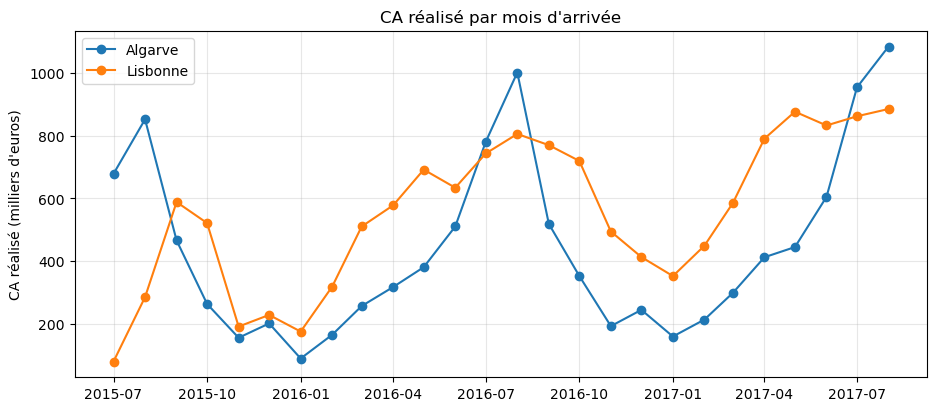

Mois le plus fort : 08/2017 - 1 970 182 €


In [8]:
propres["periode"] = pd.to_datetime(propres["date_arrivee"]).dt.to_period("M").dt.to_timestamp()
ca_mensuel = propres[propres["annulee"] == 0].groupby(["periode", "hotel"])["ca"].sum().unstack()

fig, ax = plt.subplots(figsize=(11, 4.5))
for hotel in ca_mensuel.columns:
    ax.plot(ca_mensuel.index, ca_mensuel[hotel] / 1000, marker="o", label=hotel)
ax.set_title("CA réalisé par mois d'arrivée")
ax.set_ylabel("CA réalisé (milliers d'euros)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print("Mois le plus fort :", ca_mensuel.sum(axis=1).idxmax().strftime("%m/%Y"), "-", fr(ca_mensuel.sum(axis=1).max()), "€")

### 🔧 2.4 · Qui annule ?
Cherchez ce qui distingue les réservations annulées : comparez le taux d'annulation selon **au moins deux variables de votre choix**, et tracez chaque comparaison. Aide : une variable numérique se découpe d'abord en classes, avec `pd.cut(colonne, bornes)`.

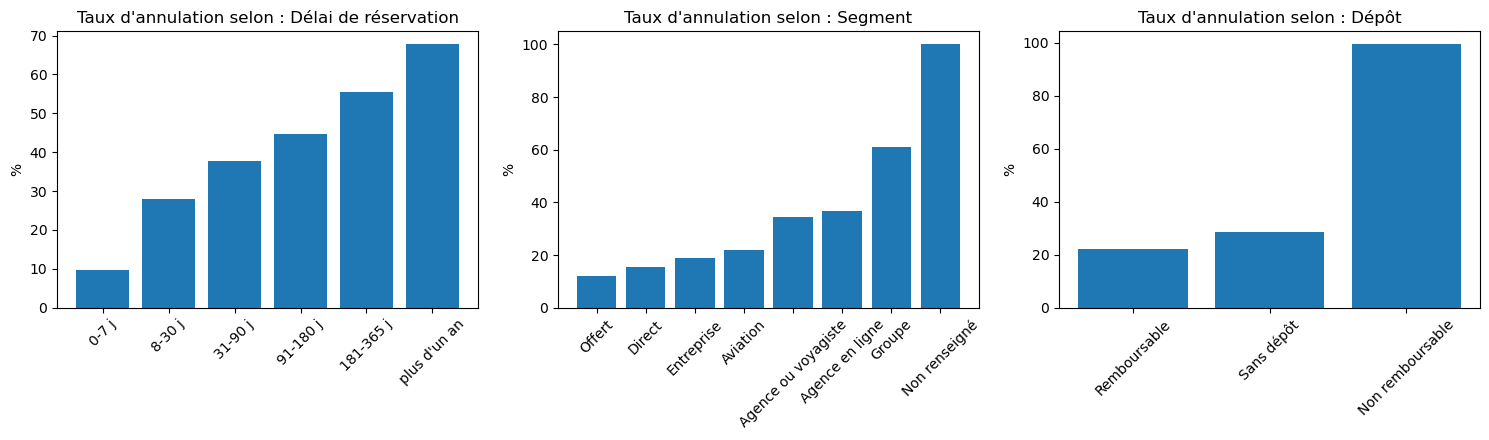

classe_delai
0-7 j            9,7 %
8-30 j          28,0 %
31-90 j         37,8 %
91-180 j        44,8 %
181-365 j       55,5 %
plus d'un an    67,7 %

segment
Offert                  12,2 %
Direct                  15,5 %
Entreprise              18,9 %
Aviation                22,1 %
Agence ou voyagiste     34,5 %
Agence en ligne         36,9 %
Groupe                  61,2 %
Non renseigné          100,0 %

depot
Remboursable        22,2 %
Sans dépôt          28,6 %
Non remboursable    99,4 %


In [9]:
# Variable 1 : le délai de réservation, découpé en classes
propres["classe_delai"] = pd.cut(propres["delai_reservation"], [-1, 7, 30, 90, 180, 365, 800],
                                 labels=["0-7 j", "8-30 j", "31-90 j", "91-180 j", "181-365 j", "plus d'un an"])
par_delai = propres.groupby("classe_delai", observed=True)["annulee"].mean()

# Variable 2 : le segment de réservation
par_segment = propres.groupby("segment")["annulee"].mean().sort_values()

# Variable 3 : le type de dépôt
par_depot = propres.groupby("depot")["annulee"].mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, serie, titre in zip(axes, [par_delai, par_segment, par_depot],
                            ["Délai de réservation", "Segment", "Dépôt"]):
    ax.bar(serie.index.astype(str), serie.values * 100)
    ax.set_title("Taux d'annulation selon : " + titre)
    ax.set_ylabel("%"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print(par_delai.map(pc).to_string()); print(); print(par_segment.map(pc).to_string()); print(); print(par_depot.map(pc).to_string())

### ✍️ 2.5 · Question
Trois constats pour la direction, chacun appuyé sur un chiffre.

*Votre réponse :*

- Premier constat, l'hôtel : Lisbonne annule 41,9 % de ses réservations contre 28,0 % en Algarve, et le CA annulé de Lisbonne (10,9 millions d'euros) atteint 76 % de son CA réalisé (14,4 millions), alors qu'en Algarve il en représente 50 % (5,8 millions contre 11,6 millions). Au total, 37,3 % des réservations disparaissent et 16,7 millions d'euros de CA attendu ne sont pas facturés, face à 26,0 millions réalisés.
- Deuxième constat, le délai : plus on réserve tôt, plus on annule. Une réservation faite dans les 7 jours est annulée dans 9,7 % des cas, contre 55,5 % entre 181 et 365 jours et 67,7 % au-delà d'un an. Côté segment, les groupes annulent à 61,2 %, contre 15,5 % pour les réservations directes et 18,9 % pour les entreprises.
- Troisième constat, le dépôt : 99,4 % des réservations à dépôt non remboursable sont annulées (14 586 réservations), contre 28,6 % sans dépôt. C'est contraire à ce qu'on attendrait d'un dépôt censé décourager l'annulation, et je pense qu'il vaut mieux vérifier avec l'hôtel comment ce champ est rempli (par exemple s'il est renseigné seulement après l'annulation) avant d'en tirer une règle de gestion.

# Étape 3 · Prévoir les annulations

L'outil demandé doit dire, **au moment de la réservation**, si elle risque d'être annulée. Il ne peut donc utiliser que des informations **connues à ce moment-là** : c'est la règle contre la fuite de données, vue au TD 1. Le notebook de classification de la première heure vous sert de modèle.

### ✍️ 3.1 · Question
Quelles colonnes gardez-vous pour prévoir ? Pour chaque colonne écartée, dites pourquoi.

*Votre réponse :*

- Colonnes gardées : hotel, mois (le mois d'arrivée), delai_reservation, nuits, adultes, enfants, segment, type_client, client_habitue, annulations_precedentes, depot et prix_nuit. Toutes sont connues le jour de la réservation (le prix convenu, les nuits réservées, le dépôt demandé, l'historique du client).
- Colonnes écartées : statut_final et annulee, car statut_final est la réponse elle-même (annulee n'est que ce statut réécrit en 0 ou 1) ; chambre_changee, car la chambre n'est attribuée qu'à l'arrivée ; demandes_speciales, car elles peuvent s'ajouter après la réservation, donc je ne peux pas garantir que la valeur du fichier était connue à ce moment ; reservation, qui n'est qu'un numéro sans lien avec le comportement du client ; date_arrivee, remplacée par le mois, car une date complète ne servirait qu'à repérer les périodes déjà vues ; annee, car le modèle est entraîné sur 2015 et 2016 et testé sur 2017, une année qu'il n'a jamais vue, et il ne saurait pas l'utiliser.
- Point de vigilance : depot et annulations_precedentes sont très liés à l'annulation (99,4 % pour les dépôts non remboursables, 94,5 % pour les clients avec exactement une annulation précédente). Je les garde car ils sont censés être connus à la réservation, mais je teste plus bas le modèle sans depot pour voir ce qu'il reste.

### 🔧 3.2 · X et y
Préparez `X`, avec les colonnes retenues en 3.1, et `y`, la cible. Les colonnes qualitatives doivent devenir des variables indicatrices, comme les mois au TD 1. Aide : `pd.get_dummies(tableau, columns=[...], dtype=int)`.

In [10]:
colonnes = ["hotel", "mois", "delai_reservation", "nuits", "adultes", "enfants", "segment",
            "type_client", "client_habitue", "annulations_precedentes", "depot", "prix_nuit"]

X = pd.get_dummies(propres[colonnes], columns=["hotel", "mois", "segment", "type_client", "depot"], dtype=int)
y = propres["annulee"]
print(X.shape[0], "lignes,", X.shape[1], "colonnes")

118563 lignes, 36 colonnes


### 🔧 3.3 · Le découpage chronologique
Entraînement : les arrivées **avant le 1er janvier 2017**. Test : les arrivées de 2017. Affichez la taille des deux jeux. Aide : une date écrite année-mois-jour se compare comme du texte.

In [11]:
est_train = propres["date_arrivee"] < "2017-01-01"        # comparaison de textes année-mois-jour
X_train, y_train = X[est_train],  y[est_train]
X_test,  y_test  = X[~est_train], y[~est_train]
print("Entraînement (2015-2016) :", fr(len(X_train)), "réservations, taux d'annulation", pc(y_train.mean()))
print("Test (2017)              :", fr(len(X_test)),  "réservations, taux d'annulation", pc(y_test.mean()))

Entraînement (2015-2016) : 78 054 réservations, taux d'annulation 36,4 %
Test (2017)              : 40 509 réservations, taux d'annulation 38,8 %


### 🔧 3.4 · La référence
Calculez, sur le jeu de test, l'exactitude d'une référence simple.

In [12]:
# Référence : on prévoit que personne n'annule (la classe la plus fréquente de l'entraînement)
exactitude_reference = 1 - y_test.mean()
print("Exactitude de la référence \"personne n'annule\" sur le test :", pc(exactitude_reference))

Exactitude de la référence "personne n'annule" sur le test : 61,2 %


### 🔧 3.5 · Le modèle
Entraînez une régression logistique, puis évaluez-la sur le jeu de test : matrice de confusion, exactitude, précision, rappel. Aide technique : écrivez `LogisticRegression(max_iter=3000)`, pour laisser à l'algorithme assez d'étapes ; l'entraînement prend quelques secondes.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# solveur exact : le résultat est le même sur toutes les machines
modele = LogisticRegression(solver="newton-cholesky", max_iter=3000).fit(X_train, y_train)
proba = modele.predict_proba(X_test)[:, 1]
prevision = (proba >= 0.5).astype(int)

print("Matrice de confusion (lignes : réel 0/1, colonnes : prévu 0/1)")
print(confusion_matrix(y_test, prevision))
print("Exactitude :", pc(accuracy_score(y_test, prevision)), "(référence :", pc(exactitude_reference) + ")")
print("Précision  :", pc(precision_score(y_test, prevision)))
print("Rappel     :", pc(recall_score(y_test, prevision)))

Matrice de confusion (lignes : réel 0/1, colonnes : prévu 0/1)
[[23785   994]
 [10259  5471]]
Exactitude : 72,2 % (référence : 61,2 %)
Précision  : 84,6 %
Rappel     : 34,8 %


### 🔧 3.6 · Le seuil
Calculez la précision et le rappel pour plusieurs seuils.

In [14]:
lignes = []
for seuil in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= seuil).astype(int)
    lignes.append({"seuil": seuil, "exactitude": pc(accuracy_score(y_test, p)),
                   "précision": pc(precision_score(y_test, p)), "rappel": pc(recall_score(y_test, p)),
                   "réservations signalées": fr(p.sum())})
pd.DataFrame(lignes).set_index("seuil")

,exactitude,précision,rappel,réservations signalées
seuil,,,,
0.2,"54,9 %","46,0 %","91,6 %",31 360
0.3,"65,1 %","53,4 %","80,4 %",23 682
0.4,"72,3 %","67,5 %","55,5 %",12 936
0.5,"72,2 %","84,6 %","34,8 %",6 465
0.6,"71,4 %","96,8 %","27,3 %",4 427
0.7,"71,2 %","98,2 %","26,3 %",4 215
0.8,"71,2 %","98,4 %","26,3 %",4 198


### ✍️ 3.7 · Question
Une annulation non prévue laisse une chambre vide. Une fausse alerte peut pousser l'hôtel à surréserver, puis à refuser un client à son arrivée. Quel seuil recommandez-vous, et pour quel usage ?

*Votre réponse :*

- Avec un seuil de 0,3, le modèle repère 80,4 % des annulations (rappel) mais seulement 53,4 % des réservations signalées s'annulent vraiment (précision). Avec un seuil de 0,6, c'est l'inverse : 96,8 % des réservations signalées s'annulent, mais on n'en repère que 27,3 %.
- Je recommande deux seuils selon l'usage. Pour surréserver, c'est-à-dire vendre plus de chambres que la capacité en comptant sur les annulations, il faut un seuil haut, 0,6 ou 0,7 : une fausse alerte coûte cher (un client refusé à son arrivée), donc je veux une précision proche de 97 % même si je ne repère qu'un peu plus d'un quart des annulations.
- Pour un usage moins risqué, comme relancer ou appeler les clients dont la réservation est à risque, ou prévoir le nombre de chambres qui seront probablement libres, un seuil bas de 0,3 convient mieux : une fausse alerte ne coûte qu'un appel, et on évite de laisser des chambres vides. Au seuil par défaut de 0,5, la précision est de 84,6 % et le rappel de 34,8 %, un compromis qui ne sert vraiment ni l'un ni l'autre usage.

### 🔧 3.8 · La fuite de données, pour voir
Ajoutez à vos variables l'une des colonnes que vous avez écartées en 3.1 parce qu'elle n'est connue qu'après coup, puis refaites le modèle. Que devient l'exactitude ?

In [ ]:
# On ajoute statut_final (connu seulement après le séjour) aux variables
X_fuite = pd.concat([X, pd.get_dummies(propres["statut_final"], prefix="statut", dtype=int)], axis=1)
modele_fuite = LogisticRegression(solver="newton-cholesky", max_iter=3000).fit(X_fuite[est_train], y_train)
prevision_fuite = modele_fuite.predict(X_fuite[~est_train])
print("Exactitude avec fuite :", pc(accuracy_score(y_test, prevision_fuite)))

# Bonus : le modèle de l'étape 3.5 sans la variable depot, pour voir ce qu'il reste
X_sans_depot = X.drop(columns=[c for c in X.columns if c.startswith("depot_")])
modele_sd = LogisticRegression(solver="newton-cholesky", max_iter=3000).fit(X_sans_depot[est_train], y_train)
p_sd = (modele_sd.predict_proba(X_sans_depot[~est_train])[:, 1] >= 0.5).astype(int)
print("Sans depot : exactitude", pc(accuracy_score(y_test, p_sd)), "- précision", pc(precision_score(y_test, p_sd)),
      "- rappel", pc(recall_score(y_test, p_sd)), "(référence :", pc(exactitude_reference) + ")")

Exactitude avec fuite : 100,0 %
Sans depot : exactitude 69,6 % - précision 65,1 % - rappel 46,5 % (référence : 61,2 %)


### ✍️ 3.9 · Question
Pourquoi ce modèle presque parfait est-il inutilisable ?

*Votre réponse :*

- Avec statut_final, l'exactitude passe de 72,2 % à 100 %, parce que cette colonne contient la réponse : "Annulée" et "Non présenté" valent annulee = 1, "Séjour effectué" vaut 0. Le modèle n'a rien appris, il a recopié la cible.
- Il est inutilisable parce que, le jour de la réservation, on ne connaît pas encore le statut final, c'est justement ce qu'on cherche à prévoir. L'outil serait parfait sur un fichier d'archives et ne servirait à rien en vrai, car la colonne ne pourrait pas être remplie.
- Le modèle honnête, lui, reste utile : sans la variable depot, qui est la plus suspecte, il garde 69,6 % d'exactitude contre 61,2 % pour la référence, ce qui montre que le résultat de 72,2 % ne repose pas seulement sur elle.

# Étape 4 · Le tableau de bord (TD 3)
Construisez une application **Streamlit** qui présente vos indicateurs (étape 2) et votre outil de prévision (étape 3), puis mettez-la **en ligne**. Vous rendrez **son lien** : n'importe qui doit pouvoir ouvrir votre tableau de bord depuis un navigateur, sans compte.

**Ce que montre le tableau de bord, c'est vous qui le décidez** : quels indicateurs, quels filtres, quels graphiques, quel seuil. Un assistant d'IA peut écrire le code avec vous ; il ne fait pas les choix à votre place.

**Avant de commencer** : un compte sur github.com, et une connexion à share.streamlit.io avec ce compte GitHub. Rien à installer : tout se fait dans le navigateur.

## Travailler avec un assistant d'IA : la méthode
1. **Écrivez votre cahier des charges avant d'ouvrir l'IA** : ce que le tableau de bord doit montrer, pour qui, et comment chaque chiffre se calcule. Ce sont vos réponses des étapes 1 à 3.
2. **Donnez le cadre** : qui vous êtes, ce que vous construisez, avec quels outils (Streamlit, Streamlit Community Cloud, un navigateur seulement), et vos données (ce qu'est une ligne, les colonnes utiles).
3. **Avancez par petites étapes** : une première version simple, mise en ligne tout de suite, puis un ajout à la fois. Demandez des fichiers complets et commentés.
4. **Vérifiez chaque version** : les chiffres affichés doivent être ceux de votre notebook. Ce que l'IA n'a pas vérifié, c'est à vous de le faire.
5. **En cas d'erreur**, donnez le message complet (menu *Manage app* de l'application) et votre fichier `app.py`.
6. **Gardez vos prompts** : vous les recopierez dans la section « Usage de l'IA ».

## Des trames de prompts
Les trames donnent la forme ; tout ce qui est entre crochets vient de votre travail.
```text
Je suis étudiant en master de contrôle de gestion et je débute en Python. Je veux construire [ce que vous construisez, et pour qui] avec Streamlit, puis le publier sur Streamlit Community Cloud ; je n'ai qu'un navigateur. Mes données : [ce qu'est une ligne, les colonnes utiles]. Guide-moi étape par étape, avec des fichiers complets commentés en français, et attends ma confirmation avant chaque nouvelle étape.
```
```text
Ajoute à mon application [ce que vous voulez ajouter], calculé ainsi : [votre définition, tirée du notebook]. Donne-moi le fichier app.py complet et explique ce que tu as modifié.
```
```text
Explique-moi pas à pas comment publier mon application sur Streamlit Community Cloud à partir d'un dépôt GitHub, sans rien installer.
```
```text
Mon application affiche cette erreur : [le message complet]. Voici mon app.py : [le fichier]. Explique la cause en une phrase, puis donne-moi le fichier corrigé.
```

**Avant de rendre** : le lien s'ouvre dans une fenêtre de navigation privée ; les chiffres affichés sont ceux de votre notebook ; l'outil de prévision respecte vos choix de l'étape 3 ; vous savez expliquer chaque partie de `app.py`.

# Le lien de votre tableau de bord
Collez ici le lien de votre application en ligne. Il se termine par `.streamlit.app` et doit s'ouvrir sans compte.

*Votre lien :*

https://projet-courtes-diawara-leroux.streamlit.app/

# Note pour la direction
En 10 à 15 lignes : les chiffres clés, ce qui explique les annulations, ce que le modèle permet et ce qu'il ne permet pas, votre recommandation. Chaque chiffre doit venir d'une cellule de ce notebook.

*Votre note :*

Sur 118 563 réservations propres, 37,3 % sont annulées, avec un écart net entre Lisbonne (41,9 %) et l'Algarve (28,0 %). Les deux hôtels ont facturé 26,0 millions d'euros pour 254 282 nuits vendues, à 102,20 € la nuit en moyenne, et les annulations ont fait perdre 16,7 millions d'euros de CA attendu, dont 10,9 millions à Lisbonne.

Les annulations dépendent surtout du délai et du type de réservation : 9,7 % pour une réservation faite moins d'une semaine à l'avance contre 67,7 % au-delà d'un an, et 61,2 % pour les groupes contre 15,5 % pour les réservations directes.

Le modèle (une régression logistique entraînée sur 2015 et 2016, testée sur 2017) n'utilise que des informations connues à la réservation. Il atteint 72,2 % d'exactitude contre 61,2 % pour la référence "personne n'annule". À 0,6, 96,8 % des réservations signalées s'annulent mais il n'en repère que 27,3 % ; à 0,3, il en repère 80,4 % avec une précision de 53,4 %. Il donne un risque et non une certitude, et les variables dépôt et annulations précédentes sont à vérifier avec l'hôtel : 99,4 % des dépôts non remboursables sont annulés, et sans la variable dépôt l'exactitude tombe à 69,6 %.

Je recommande le seuil de 0,6 pour une surréservation prudente et le seuil de 0,3 pour choisir qui relancer, en refaisant les mesures à chaque saison, car le modèle n'a vu que deux ans de données.

# Usage de l'IA
Pour quoi faire, avec quels prompts, et ce que vous avez vérifié ou corrigé.

*Votre réponse :*

J'ai utilisé l'assistant d'IA (Claude) pour écrire le code du notebook, les réponses aux questions, la note pour la direction et le fichier app.py de l'application Streamlit, à partir du sujet fourni par le professeur, du dictionnaire des variables et du fichier reservations_hotels.csv. Je l'ai aussi utilisé pour comprendre une erreur et pour vérifier mes réponses. Mon prompt de départ, envoyé avec trois fichiers joints (consignes.txt, le notebook du projet et reservations_hotels.csv), était le suivant :

```text
Voici le projet à rendre dans le cadre du TD2 de Machine Learning (première partie dans la conv "TD2 - ML", avec dans consignes.txt quelques consignes que j'ai noté pendant la présentation du prof
```

Mes prompts suivants, tels que je les ai envoyés :

```text
Le 1.3 tu réponds à toutes les sous questions ?
```
```text
Pour l'étape 4, pour les sections "Le lien de votre tableau de bord", "Note pour la direction",  "Usage de l'IA", ça réponds aux consignes ?
```

Pour l'erreur de la cellule 2.2, j'ai envoyé une capture de l'avertissement, puis le message complet de l'erreur KeyError.

Ce que j'ai vérifié et corrigé :

- Cellule 1.3 : elle ne répondait pas à toutes les questions de l'énoncé (valeur négative, nulle, trop grande), je l'ai fait compléter avec les maximums d'adultes, d'enfants et d'annulations précédentes.
- Réponse 1.5 : j'ai fait vérifier dans les données deux affirmations non contrôlées (657 des 1 244 prix nuls sont du segment "Offert", les 12 réservations de plus de 10 adultes sont des groupes en Algarve), ce qui a corrigé une phrase fausse sur les 100 lignes à plus de 20 annulations précédentes, qui viennent en réalité de 5 dates d'arrivée en 2015 et non de "clients très réguliers".
- Cellule 2.2 : le FutureWarning a été supprimé avec include_groups=False, et l'erreur KeyError "ca" venait de l'ordre d'exécution, corrigée en relançant la 1.6 puis la 1.7.
- Chiffres du modèle : ils changeaient d'une machine à l'autre (84,3 %, 84,6 % ou 84,7 % de précision à 0,5), car le solveur par défaut s'arrête avant la solution exacte. Je l'ai fait remplacer par le solveur newton-cholesky, qui donne le même résultat partout, puis j'ai mis à jour les textes (rappel à 0,3 de 80,4 %, exactitude sans depot de 69,6 %) pour que le notebook et le tableau de bord affichent les mêmes chiffres.

Ce que j'ai décidé moi-même :

- Nettoyage : retirer les réservations de 0 nuit, celles sans voyageur, le prix négatif et le prix à 5 400 € la nuit ; garder les prix à 0 € (séjours offerts), les grands groupes et les lignes identiques, qui ne sont pas des doublons faute d'identifiant client.
- Indicateurs : CA réalisé sur les séjours effectués, prix moyen pondéré par les nuits, CA annulé sur les réservations annulées.
- Modèle : garder depot malgré son lien suspect avec l'annulation (en testant aussi le modèle sans cette variable) et écarter demandes_speciales par prudence, car elle peut changer après la réservation.
- Seuils : 0,6 pour la surréservation, 0,3 pour les relances.
- Tableau de bord : les cinq indicateurs avec deux filtres (hôtel, année), un menu pour suivre l'indicateur choisi mois par mois, deux graphiques sur les causes (délai et segment), un onglet de prévision avec deux boutons de seuil, les mesures sur 2017 et un test de réservation, et un avertissement sur le dépôt (99,4 % des dépôts non remboursables sont annulés, à vérifier avec l'hôtel).